In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import string
import os
from PIL import Image
import glob
from pickle import dump, load
import time

# Deep Learning Libraries
from keras.preprocessing import sequence
from keras.models import Model
from keras.layers import LSTM, Embedding, Dense, add, Dropout, Input
from keras.applications.inception_v3 import InceptionV3, preprocess_input
from keras.preprocessing.image import load_img, img_to_array
from keras.utils import to_categorical
from collections import Counter

In [2]:
# Function to load a text file into memory
def load_doc(filename):
    with open(filename, 'r') as file:
        text = file.read()
    return text

# Function to parse the loaded text into a dictionary
def load_descriptions(doc):
    mapping = dict()
    lines = doc.strip().split('\n')
    # Skip header if present
    if lines[0].lower().startswith('image'):
        lines = lines[1:]
    for line in lines:
        tokens = line.split(',', 1)
        if len(tokens) < 2:
            continue
        # The first token is image_id (e.g., '1000268201_693b08cb0e.jpg#0')
        # The second is the description
        image_id, image_desc = tokens[0], tokens[1]
        # Extract the filename
        image_id = image_id.split('.')[0]
        # Store the description
        if image_id not in mapping:
            mapping[image_id] = list()
        mapping[image_id].append(image_desc)
    return mapping

# Load the captions
captions_file = 'E:\project_img_caption\data\captions.txt' # Corrected path
doc = load_doc(captions_file)

# Parse descriptions
descriptions = load_descriptions(doc)
print(f'Successfully loaded {len(descriptions)} images.')

# --- Visualization ---
print("\n--- Example Captions for one image ---")
image_id_example = list(descriptions.keys())[0]
print(f"Image ID: {image_id_example}")
for caption in descriptions[image_id_example]:
    print(f"- {caption}")

Successfully loaded 8091 images.

--- Example Captions for one image ---
Image ID: 1000268201_693b08cb0e
- A child in a pink dress is climbing up a set of stairs in an entry way .
- A girl going into a wooden building .
- A little girl climbing into a wooden playhouse .
- A little girl climbing the stairs to her playhouse .
- A little girl in a pink dress going into a wooden cabin .


## 2. Text Data Cleaning & Preprocessing

We'll clean the captions by removing punctuation, converting to lowercase, and filtering out short/long captions. We'll visualize a few examples before and after cleaning.

In [3]:
def clean_descriptions(descriptions):
    # Prepare a translation table to remove punctuation
    table = str.maketrans('', '', string.punctuation)
    for key, desc_list in descriptions.items():
        for i in range(len(desc_list)):
            desc = desc_list[i]
            # Tokenize (split into words)
            desc = desc.split()
            # Convert to lower case
            desc = [word.lower() for word in desc]
            # Remove punctuation
            desc = [w.translate(table) for w in desc]
            # Remove hanging 's' and 'a'
            desc = [word for word in desc if len(word) > 1]
            # Remove tokens with numbers
            desc = [word for word in desc if word.isalpha()]
            # Re-join into a single string
            desc_list[i] = ' '.join(desc)

# Clean the descriptions
clean_descriptions(descriptions)

# --- Visualization ---
print("--- Same Example Captions (Cleaned) ---")
print(f"Image ID: {image_id_example}")
for caption in descriptions[image_id_example]:
    print(f"- {caption}")



--- Same Example Captions (Cleaned) ---
Image ID: 1000268201_693b08cb0e
- child in pink dress is climbing up set of stairs in an entry way
- girl going into wooden building
- little girl climbing into wooden playhouse
- little girl climbing the stairs to her playhouse
- little girl in pink dress going into wooden cabin


## 3. Building Vocabulary

We'll build the vocabulary from cleaned captions, show its size, and visualize the most frequent words.

 Vocabulary Size: 8763


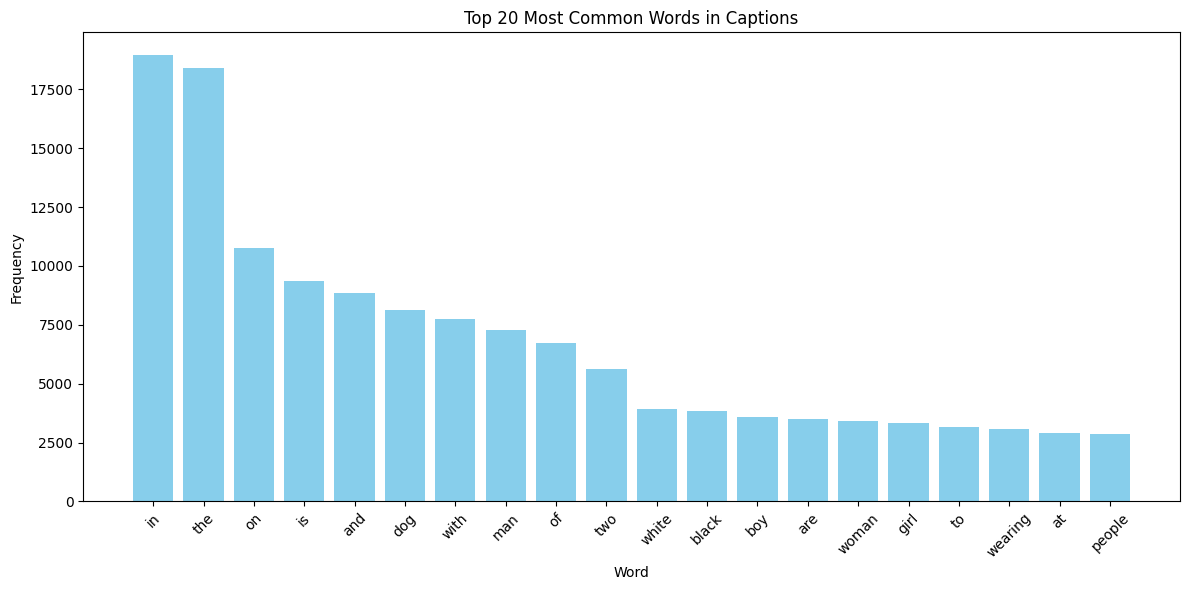

In [4]:
def to_vocabulary(descriptions):
    # Build a set of all unique words
    all_desc = set()
    for key in descriptions.keys():
        [all_desc.update(d.split()) for d in descriptions[key]]
    return all_desc

# Summarize vocabulary
vocabulary = to_vocabulary(descriptions)
print(f' Vocabulary Size: {len(vocabulary)}')

# Count word frequencies
word_freq = Counter()
for key in descriptions.keys():
    for desc in descriptions[key]:
        for word in desc.split():
            word_freq[word] += 1

# Show top 20 most frequent words
most_common = word_freq.most_common(20)
words, freqs = zip(*most_common)

plt.figure(figsize=(12, 6))
plt.bar(words, freqs, color='skyblue')
plt.xticks(rotation=45)
plt.title("Top 20 Most Common Words in Captions")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Save the cleaned descriptions to a file for later use
def save_descriptions(descriptions, filename):
    lines = list()
    for key, desc_list in descriptions.items():
        for desc in desc_list:
            lines.append(f'{key} {desc}')
    data = '\n'.join(lines)
    with open(filename, 'w') as file:
        file.write(data)
        
save_descriptions(descriptions, 'descriptions.txt')

In [ ]:
#test with removing stop words, and steming 

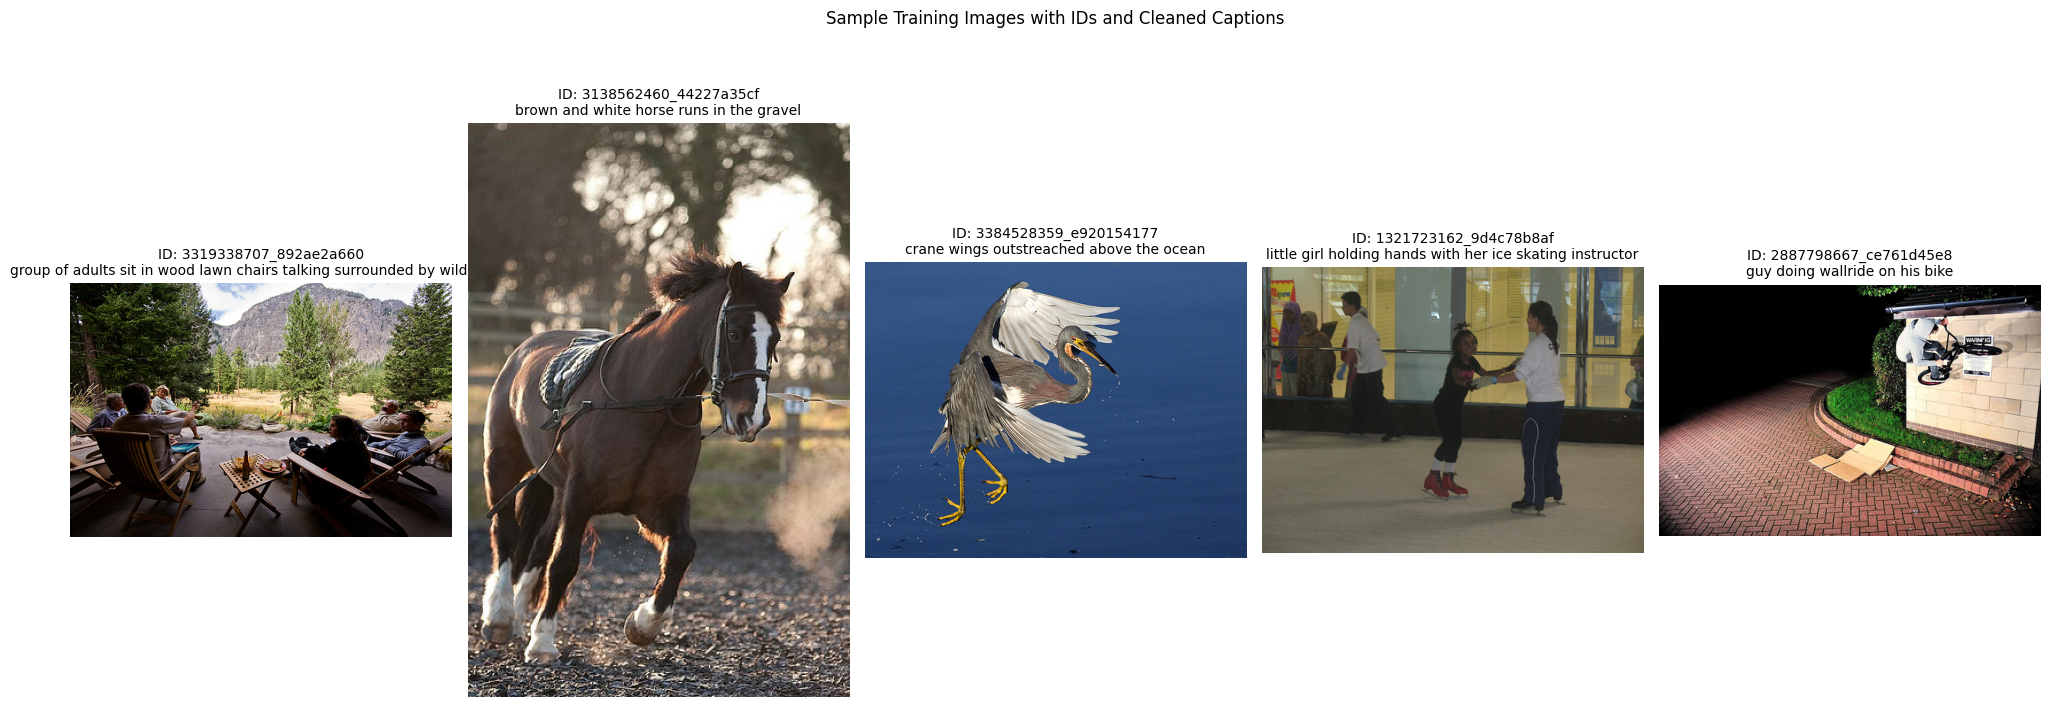

In [11]:
import random
from PIL import Image

# Visualize 5 random training images with their descriptive IDs and cleaned captions
sample_ids = random.sample(list(train_descriptions.keys()), 5)
plt.figure(figsize=(20, 8))
for i, img_id in enumerate(sample_ids):
    img_path = os.path.join(images_dir, img_id + '.jpg')
    img = Image.open(img_path)
    plt.subplot(1, 5, i+1)
    plt.imshow(img)
    plt.axis('off')
    # Get cleaned caption (remove startseq/endseq)
    caption = train_descriptions[img_id][0].replace('startseq ', '').replace(' endseq', '')
    plt.title(f'ID: {img_id}\n{caption}', fontsize=10)
plt.suptitle('Sample Training Images with IDs and Cleaned Captions')
plt.tight_layout()
plt.show()

## 4. Preparing Training and Testing Sets
Goal: Split our dataset. We need a training set to teach the model and a testing set to evaluate its performance on unseen images. We'll also add special startseq and endseq tokens to each training caption. These markers tell the model when a sentence begins and ends.

## 6: Image Feature Extraction (The Encoder)

 Use the powerful, pre-trained InceptionV3 model to look at each image and convert it into a 2048-element feature vector. This vector is a rich numerical summary of the image's content.

In [10]:
# Set your Flickr8k directory
from keras.preprocessing.image import load_img, img_to_array

# ========== Step 1: Define All File and Directory Paths ==========
flickr8k_dir = 'E:/project_img_caption/data/'
images_dir = os.path.join(flickr8k_dir, 'Images') # Corrected path for images
descriptions_file = os.path.join(flickr8k_dir, 'captions.txt')
train_images_file = os.path.join(flickr8k_dir, 'Flickr_8k.trainImages.txt')
features_file = "encoded_train_images.pkl" # Define the output file path

# Helper function to load text files
def load_doc(filename):
    with open(filename, 'r') as file:
        text = file.read()
    return text

# ========== Step 2: Load the List of Training Image IDs ==========
def load_set(filename):
    doc = load_doc(filename)
    dataset = set()
    for line in doc.split('\n'):
        if len(line) < 1:
            continue
        identifier = line.split('.')[0]
        dataset.add(identifier)
    return dataset

# Load training dataset identifiers
train_ids = load_set(train_images_file)
print(f'Found {len(train_ids)} training image IDs.')

# ========== Step 3: Extract and Save Image Features ==========
# Load the InceptionV3 model
inception_model = InceptionV3(weights='imagenet')
# Remove the last classification layer to get a feature extractor
model_new = Model(inception_model.input, inception_model.layers[-2].output)

def preprocess_image(image_path):
    img = load_img(image_path, target_size=(299, 299))
    x = img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = preprocess_input(x)
    return x

def encode(image):
    image = preprocess_image(image)
    feature_vector = model_new.predict(image, verbose=0)
    return feature_vector

# --- Start Encoding Process ---
start = time.time()
encoding_train = {}

print("Starting image feature extraction (this may take a while)...")
for img_id in train_ids:
    # Use the corrected path for the images directory
    img_path = os.path.join(images_dir, img_id + '.jpg')
    if os.path.exists(img_path):
        encoding_train[img_id] = encode(img_path)

print(f"Time taken to encode training images: {time.time() - start:.2f}s")

# Save features to a pickle file
with open(features_file, "wb") as encoded_pickle:
    dump(encoding_train, encoded_pickle)
print(f"Saved features for {len(encoding_train)} images to {features_file}")

# --- Visualization ---
train_features = load(open(features_file, "rb"))
print(f'\nSuccessfully loaded {len(train_features)} encoded training images.')

# To avoid errors, get an example key directly from the dictionary you just created
if train_features:
    example_id_from_train_set = list(train_features.keys())[0]
    example_feature = train_features[example_id_from_train_set]
    print(f"Shape of one image feature vector: {example_feature.shape}")

Found 6000 training image IDs.
Starting image feature extraction (this may take a while)...
Time taken to encode training images: 638.00s
Saved features for 6000 images to encoded_train_images.pkl

Successfully loaded 6000 encoded training images.
Shape of one image feature vector: (1, 2048)


## 6. Data Preparation for the Decoder

Prepare the text data for the LSTM decoder. This involves:
Creating a final vocabulary from only the training captions.
Mapping each word to a unique integer index (wordtoix) and back (ixtoword).
Finding the maximum caption length to standardize the input shape.

In [15]:
# Create a list of all training captions
all_train_captions = []
for key, val in train_descriptions.items():
    for cap in val:
        all_train_captions.append(cap)

# Consider only words that occur at least 10 times
word_count_threshold = 10
word_counts = {}
for sent in all_train_captions:
    for w in sent.split(' '):
        word_counts[w] = word_counts.get(w, 0) + 1

vocab = [w for w in word_counts if word_counts[w] >= word_count_threshold]
print(f'Filtered vocabulary: {len(word_counts)} words -> {len(vocab)} words')

# Create word-to-index and index-to-word mappings
ixtoword = {}
wordtoix = {}
ix = 1
for w in vocab:
    wordtoix[w] = ix
    ixtoword[ix] = w
    ix += 1

vocab_size = len(ixtoword) + 1 # Add 1 for the 0 padding

# Find the maximum caption length
max_length = max(len(d.split()) for d in all_train_captions)
print(f'Maximum description length: {max_length}')

# --- Visualization ---
print("\n--- Example Mappings ---")
print(f"Word 'dog' is mapped to index: {wordtoix.get('dog', 'Not in vocab')}")
print(f"Index 50 is mapped to word: {ixtoword.get(50, 'N/A')}")

Filtered vocabulary: 7668 words -> 1667 words
Maximum description length: 34

--- Example Mappings ---
Word 'dog' is mapped to index: 25
Index 50 is mapped to word: covered


## 7. Creating a Data Generator

Create a function that feeds data to the model in batches. It's not feasible to load all image-caption pairs into memory at once. A generator yields data on-the-fly, making training memory-efficient.

The generator creates pairs for training. For a caption startseq A B C endseq, it will create:

Image + startseq -> predict A

Image + startseq A -> predict B

Image + startseq A B -> predict C

In [ ]:
def data_generator(descriptions, photos, wordtoix, max_length, num_photos_per_batch):
    X1, X2, y = list(), list(), list()
    n = 0
    while 1:
        for key, desc_list in descriptions.items():
            n += 1
            photo = photos[key][0]
            for desc in desc_list:
                seq = [wordtoix[word] for word in desc.split(' ') if word in wordtoix]
                for i in range(1, len(seq)):
                    in_seq, out_seq = seq[:i], seq[i]
                    in_seq = sequence.pad_sequences([in_seq], maxlen=max_length)[0]
                    out_seq = to_categorical([out_seq], num_classes=vocab_size)[0]
                    
                    X1.append(photo)
                    X2.append(in_seq)
                    y.append(out_seq)

            if n == num_photos_per_batch:
                yield ((np.array(X1), np.array(X2)), np.array(y))
                X1, X2, y = list(), list(), list()
                n = 0

## 8. Defining the Model 

Define our complete encoder-decoder model in Keras. This involves creating two input streams (one for images, one for text) and merging them to predict the next word.

In [17]:
# Image feature extractor model
inputs1 = Input(shape=(2048,))
fe1 = Dropout(0.5)(inputs1)
fe2 = Dense(256, activation='relu')(fe1)

# Sequence model
inputs2 = Input(shape=(max_length,))
se1 = Embedding(vocab_size, 256, mask_zero=True)(inputs2) # Using 256-dim embedding
se2 = Dropout(0.5)(se1)
se3 = LSTM(256)(se2)

# Decoder (merging both models)
decoder1 = add([fe2, se3])
decoder2 = Dense(256, activation='relu')(decoder1)
outputs = Dense(vocab_size, activation='softmax')(decoder2)

# Tie it all together
model = Model(inputs=[inputs1, inputs2], outputs=outputs)
model.compile(loss='categorical_crossentropy', optimizer='adam')

# --- Visualization ---
print(model.summary())

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 34)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 2048)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 34, 256)   │    427,008 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 34, 256)   │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 34)        │          0 │ input_layer_3[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    524,544 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 256)       │    525,312 │ dropout_1[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 256)       │          0 │ dense[0][0],      │
│                     │                   │            │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │     65,792 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1668)      │    428,676 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,971,332 (7.52 MB)

 Trainable params: 1,971,332 (7.52 MB)

 Non-trainable params: 0 (0.00 B)

None


### 10.Training the Model

 Train our defined model using the data generator. We will run it for several epochs, allowing it to learn the patterns between images and captions.

In [21]:
epochs = 20
number_pics_per_batch = 3
steps = len(train_descriptions) // number_pics_per_batch

# Create the generator
generator = data_generator(train_descriptions, train_features, wordtoix, max_length, number_pics_per_batch)

# Fit the model using the correct function name
model.fit(generator, epochs=epochs, steps_per_epoch=steps, verbose=1)

# Save the trained model
model.save('image_captioning_model.h5')

TypeError: `output_signature` must contain objects that are subclass of `tf.TypeSpec` but found <class 'list'> which is not.

### 11. generate captions and infrence 

In [ ]:
# Function to generate a caption
def greedySearch(photo_feature):
    in_text = 'startseq'
    for i in range(max_length):
        sequence = [wordtoix[w] for w in in_text.split() if w in wordtoix]
        sequence = sequence.pad_sequences([sequence], maxlen=max_length)
        yhat = model.predict([photo_feature, sequence], verbose=0)
        yhat = np.argmax(yhat)
        word = ixtoword[yhat]
        in_text += ' ' + word
        if word == 'endseq':
            break
    final = in_text.split()
    final = final[1:-1]
    final = ' '.join(final)
    return final

# --- Visualization ---
# Load a test image and generate a caption
test_ids = load_set('Flickr_8k.testImages.txt')
pic_id = list(test_ids)[0]
pic_path = image_dir + pic_id + '.jpg'

# Encode the test image
test_image_feature = encode(pic_path)

# Generate caption
generated_caption = greedySearch(test_image_feature)
print(f"Generated Caption: {generated_caption}")

# Display the image
image = Image.open(pic_path)
plt.imshow(image)
plt.title(f"Generated: {generated_caption}")
plt.axis('off')
plt.show()

# genrating captions for BLEU and METEOR 

In [ ]:
!pip install nltk

import nltk
nltk.download('wordnet')
nltk.download('omw-1.4')

In [ ]:
from tqdm import tqdm # A library to show progress bars
from nltk.translate.bleu_score import corpus_bleu
from nltk.translate.meteor_score import meteor_score
from pycocoevalcap.cider.cider import Cider
from pycocoevalcap.bleu.bleu import Bleu

# --- Load Test Data ---
# Load test set image IDs
test_ids = load_set('Flickr_8k.testImages.txt')
print(f'Test Images: {len(test_ids)}')

# Load test descriptions (references)
# We need to modify our load_clean_descriptions to NOT add start/end tokens
def load_reference_descriptions(filename, dataset):
    doc = load_doc(filename)
    descriptions = dict()
    for line in doc.split('\n'):
        tokens = line.split()
        image_id, image_desc = tokens[0], tokens[1:]
        if image_id in dataset:
            if image_id not in descriptions:
                descriptions[image_id] = list()
            # Store the raw description
            descriptions[image_id].append(' '.join(image_desc))
    return descriptions

# Test descriptions
test_descriptions = load_reference_descriptions('descriptions.txt', test_ids)
print(f'Reference descriptions for testing: {len(test_descriptions)}')

# --- Generate Predictions ---
# We need to encode all test images first
encoding_test = {}
image_dir = 'data/images/'
for img_id in tqdm(test_ids, desc="Encoding Test Images"):
    img_path = image_dir + img_id + '.jpg'
    if os.path.exists(img_path):
        encoding_test[img_id] = encode(img_path)

# Dictionary to store the actual and predicted captions
actual, predicted = dict(), dict()

for key, photo_feature in tqdm(encoding_test.items(), desc="Generating Captions"):
    # Generate a caption for the image
    yhat = greedySearch(photo_feature)
    # Get the reference captions
    references = test_descriptions[key]
    
    # Store
    actual[key] = references
    predicted[key] = yhat

print(f"\nGenerated captions for {len(predicted)} test images.")

In [ ]:
# Prepare data for NLTK's corpus_bleu
actual_bleu = []
predicted_bleu = []

for key in actual:
    # References for one image need to be a list of lists of words
    refs_for_image = [d.split() for d in actual[key]]
    actual_bleu.append(refs_for_image)
    
    # Candidate for one image is a list of words
    pred_for_image = predicted[key].split()
    predicted_bleu.append(pred_for_image)

# Calculate BLEU scores
bleu1 = corpus_bleu(actual_bleu, predicted_bleu, weights=(1.0, 0, 0, 0))
bleu2 = corpus_bleu(actual_bleu, predicted_bleu, weights=(0.5, 0.5, 0, 0))
bleu3 = corpus_bleu(actual_bleu, predicted_bleu, weights=(0.33, 0.33, 0.33, 0))
bleu4 = corpus_bleu(actual_bleu, predicted_bleu, weights=(0.25, 0.25, 0.25, 0.25))

print(f"BLEU-1: {bleu1:.4f}")
print(f"BLEU-2: {bleu2:.4f}")
print(f"BLEU-3: {bleu3:.4f}")
print(f"BLEU-4: {bleu4:.4f}")

In [ ]:
# Calculate METEOR scores (this can be slow)
total_meteor_score = 0.0
count = 0

for key in tqdm(actual, desc="Calculating METEOR"):
    # NLTK's meteor_score expects a list of reference strings and a single candidate string
    refs_for_image = actual[key]
    pred_for_image = predicted[key]
    
    # Calculate score for a single image-caption pair and add to total
    total_meteor_score += meteor_score(refs_for_image, pred_for_image)
    count += 1
    
# Average the score
average_meteor_score = total_meteor_score / count
print(f"\nAverage METEOR Score: {average_meteor_score:.4f}")